# Optimal BB84 Probe

Note the conventions used in this notebook 

- `a` is Alice's signal, which passes through to Bob
- `e`, `f` is Eve's two-qubit probe, which she stores until Alice announces the basis
- `x`, `y` is the rectilinear $\ket{0}$ and $\ket{1}$ basis via `Z` gate
- `u`, `v` is the diagonal $\ket{+}$ and $\ket{-}$ basis via `X` gate

The tensor is `(f, e, a)`, putting `a` on the top of diagrams.

In [9]:
import numpy as np
import matplotlib.pyplot as plt

from qutip import basis, tensor, ket2dm, qeye, sigmaz, entropy_vn, mesolve
from qutip_qip.circuit import QubitCircuit
from qutip_qip.operations import gate_sequence_product

In [10]:
x, y = basis(2, 0), basis(2, 1)
u, v = (x + y).unit(), (x - y).unit()

F, E, A = 0, 1, 2                    # qubit indices in the tensor order (f, e, a)
WIRES = ["", "", "f", "e", "a"]      # wire labels, bottom to top

The circuit without the noisy channel is given below.

In [11]:
def draw(circuit, wire_label=None):
    circuit.draw("matplotlib", wire_label=wire_label)

In [12]:
def build_circuit(noisy):
    qc = QubitCircuit(3)
    qc.add_gate("CNOT", controls=A, targets=E)    # gate 1: a -> e
    qc.add_gate("CNOT", controls=F, targets=A)    # gate 2: f -> a
    if noisy:
        qc.add_gate(r"$\mathcal{N}_\lambda$", targets=E)
        qc.add_gate(r"$\mathcal{N}_\lambda$", targets=F)
            
    return qc

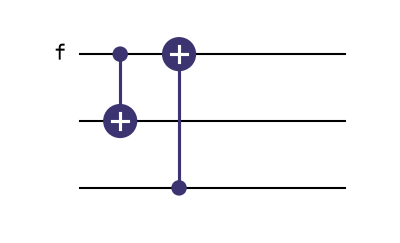

In [13]:
draw(build_circuit(noisy=False), wire_label=WIRES)

We can run the usual BB84 protocol and compair it with this to see the different QBERs.

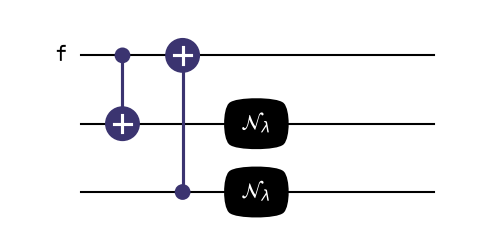

In [14]:
draw(build_circuit(noisy=True), wire_label=WIRES)

Eve picks the error rate $D$ she is willing to cause, then prepares

$$|e_0\rangle = \sqrt{1-\Delta}\,|x\rangle + \sqrt{\Delta}\,|y\rangle, \qquad
  |f_0\rangle = \sqrt{1-D}\,|x\rangle + \sqrt{D}\,|y\rangle, \qquad
  \Delta = \tfrac12 - \sqrt{D(1-D)}$$

In [15]:
def probe(D):
    Delta = 0.5 - np.sqrt(D * (1 - D))
    e0 = np.sqrt(1 - Delta) * x + np.sqrt(Delta) * y
    f0 = np.sqrt(1 - D)     * x + np.sqrt(D)     * y
    return e0, f0

running this gives ... 

## Running BB84:

In [16]:
BB84 = {"Z": (x, y), "X": (u, v)}      # basis -> (state for bit 0, state for bit 1)

def alice_prepares(bit, basis_name):
    return BB84[basis_name][bit]

def eve_attacks(U, alice_qubit, signal, probe, keep=None):
    register = list(probe)
    register.insert(signal, alice_qubit)          # drop Alice's qubit into its slot
    joint_state = ket2dm(U * tensor(register)).ptrace(signal)
    if keep is None:
        keep = signal
    return joint_state.ptrace(keep)

def bob_measures(rho, basis_name):
    s0, s1 = BB84[basis_name]
    return (float(np.real(s0.dag() * rho * s0)), float(np.real(s1.dag() * rho * s1)))

Lindbladian
$$\frac{d\rho}{dt}= -i[H,\rho] + \sum_k \left( L_k\rho L_k^\dagger -\frac12\{L_k^\dagger L_k,\rho\} \right)$$
Pick $H=0$ to isolate decoherence.
$$L_f=\sqrt{\gamma_f/2}\,(\sigma_z\otimes I), \qquad L_e=\sqrt{\gamma_e/2}\,(I\otimes\sigma_z)$$

In [17]:
def memory_collapse_operators(gamma_f, gamma_e):
    I = qeye(2)
    L_f = np.sqrt(gamma_f / 2) * tensor(sigmaz(), I)
    L_e = np.sqrt(gamma_e / 2) * tensor(I, sigmaz())

def evolve_memory(rho, times, collapse_ops):
    H = 0 * tensor(qeye(2), qeye(2))
    result = mesolve(H, rho, times, c_ops=collapse_ops, e_ops=[])
    return result.states

Helstrom Measurement
$$P_{success}=\frac{1}{2}+\frac{1}{4}\left\|\sigma_0-\sigma_1\right\|_1$$

In [18]:
def eve_guess_probability(sigma_0, sigma_1):
    difference = sigma_0 - sigma_1
    eigenvalues = np.linalg.eigvalsh(difference.full())
    trace_norm = np.sum(np.abs(eigenvalues))
    return float(0.5 + 0.25 * trace_norm)

In [19]:
def bb84_qber(circuit, signal, probe=None):
    U = gate_sequence_product(circuit.propagators())
    if probe is None:
        probe = [basis(2, 0)] * (circuit.N - 1) # |0> repeated N-1 times

    errors = {"Z": [], "X": []}

    for alice_basis in ["Z", "X"]:
        for bob_basis in ["Z", "X"]:

            if alice_basis != bob_basis:
                continue

            for bit in [0, 1]:                            
                sent     = alice_prepares(bit, alice_basis)
                received = eve_attacks(U, sent, signal, probe)
                p0, p1   = bob_measures(received, bob_basis)

                errors[alice_basis].append(p1 if bit == 0 else p0)

    Q_Z = float(np.mean(errors["Z"]))
    Q_X = float(np.mean(errors["X"]))
    return (Q_Z + Q_X) / 2

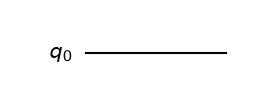

In [20]:
draw(QubitCircuit(1))

For plane bb84 with no eve

In [21]:
bb84_qber(QubitCircuit(1), signal=0)

0.0

For bb84 with standard eve where they use a cnot to "copy" (not really but entangle with it) the state since if the input is 

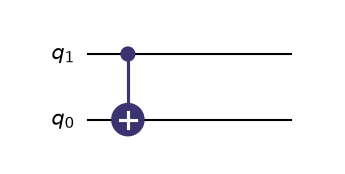

IndexError: Invalid selection index in ptrace.

In [22]:
copier = QubitCircuit(2)
copier.add_gate("CNOT", controls=1, targets=0)
draw(copier)

bb84_qber(copier, signal=1)

BB84 with optimal Eve

In [ ]:
e0, f0 = probe(0.10)
circuit = build_circuit(noisy=False)
draw(circuit)

bb84_qber(circuit, signal=A, probe=[f0, e0])

In [ ]:
import numpy as np
from qutip import basis, tensor
from qutip_qip.circuit import QubitCircuit
from qutip_qip.device import LinearSpinChain
from qutip_qip.noise import RelaxationNoise

# 1. Define your quantum circuit
qc = QubitCircuit(3)
qc.add_gate("CNOT", controls=0, targets=1)
qc.add_gate("CNOT", controls=2, targets=0)

# 2. Initialize a physical processor model (e.g., a 3-qubit linear spin chain)
processor = LinearSpinChain(num_qubits=3)

# 3. Create and add RelaxationNoise
# t1 controls the amplitude damping time scale; t2 controls dephasing
noise = RelaxationNoise(t1=10.0, t2=5.0)
processor.add_noise(noise)

# 4. Load the circuit onto the processor and run open-system evolution
processor.load_circuit(qc)
tlist = np.linspace(0, 30, 300)
init_state = tensor([basis(2, 0), basis(2, 0), basis(2, 0)])
result = processor.run_state(init_state, tlist=tlist)

In [ ]:
draw(qc)

In [2]:

import numpy as np
from qutip import (
    basis, sigmax, sigmaz, ket2dm,
    qeye, measure_observable
)

N = 1000
p = 0.0  # Noise strength (0 = ideal channel)

rng = np.random.default_rng(42)

# Computational basis
zero = basis(2, 0)
one = basis(2, 1)

# Hadamard basis
plus = (zero + one).unit()
minus = (zero - one).unit()

# (basis, bit) -> quantum state
states = {
    (0, 0): zero,
    (0, 1): one,
    (1, 0): plus,
    (1, 1): minus
}

# Alice and Bob choose random bits/bases
alice_bits = rng.integers(0, 2, N)
alice_bases = rng.integers(0, 2, N)
bob_bases = rng.integers(0, 2, N)

bob_bits = np.zeros(N, dtype=int)

for i in range(N):
    # Alice prepares her qubit
    psi = states[
        (alice_bases[i], alice_bits[i])
    ]

    rho = ket2dm(psi)

    # Quantum channel: depolarizing noise
    rho = (1 - p) * rho + p * qeye(2) / 2

    # Bob selects measurement observable
    if bob_bases[i] == 0:
        observable = sigmaz()
    else:
        observable = sigmax()

    # Bob measures the qubit
    outcome, _ = measure_observable(rho, observable)

    # Eigenvalue +1 -> bit 0; -1 -> bit 1
    bob_bits[i] = int(outcome < 0)

# Sifting: retain only matching bases
matching = alice_bases == bob_bases

alice_key = alice_bits[matching]
bob_key = bob_bits[matching]

# Overall QBER
qber = np.mean(alice_key != bob_key) if len(alice_key) else np.nan

print("Sifted bits:", len(alice_key))
print("Alice's key:", alice_key)
print("Bob's key:", bob_key)
print(f"QBER: {qber:.4f}")

# Basis-dependent QBER
for b, name in [(0, "Z"), (1, "X")]:
    mask = matching & (alice_bases == b)

    error = (
        np.mean(alice_bits[mask] != bob_bits[mask])
        if np.any(mask) else np.nan
    )

    print(f"QBER ({name}): {error:.4f}")


ImportError: cannot import name 'measure_observable' from 'qutip' (/Users/dhruvupreti/Projects/Quantum Memory BB84/.venv/lib/python3.11/site-packages/qutip/__init__.py)

In [3]:

import numpy as np
from qutip import basis, ket2dm, expect
from qutip_qip.circuit import QubitCircuit

# --------------------------------------------------
# BB84 parameters
# --------------------------------------------------

N = 1000
rng = np.random.default_rng(42)

zero = basis(2, 0)
P0 = ket2dm(zero)

alice_bits = rng.integers(0, 2, size=N)
alice_bases = rng.choice(["Z", "X"], size=N)
bob_bases = rng.choice(["Z", "X"], size=N)

bob_bits = []

# --------------------------------------------------
# Quantum communication register: Alice -> Bob
# --------------------------------------------------

register = QubitCircuit(1)

# Ideal noiseless channel (identity transformation)
register.add_gate("RZ", targets=[0], arg_value=0.0)

# --------------------------------------------------
# BB84 protocol
# --------------------------------------------------

for i in range(N):

    # 1. Alice prepares her qubit
    alice_circuit = QubitCircuit(1)

    if alice_bits[i] == 1:
        alice_circuit.add_gate("X", targets=[0])

    if alice_bases[i] == "X":
        alice_circuit.add_gate("SNOT", targets=[0])

    # Prepare quantum state |psi>
    psi = alice_circuit.run(zero)
    rho = ket2dm(psi)

    # 2. Alice sends the qubit through the register
    rho = register.run(rho)

    # 3. Bob selects his measurement basis
    bob_circuit = QubitCircuit(1)

    if bob_bases[i] == "X":
        bob_circuit.add_gate("SNOT", targets=[0])

    # Include identity gate for Z-basis measurement
    bob_circuit.add_gate("RZ", targets=[0], arg_value=0.0)

    rho = bob_circuit.run(rho)

    # 4. Bob measures in the computational basis
    p0 = float(np.real(expect(P0, rho)))
    p0 = np.clip(p0, 0.0, 1.0)

    measurement = 0 if rng.random() < p0 else 1
    bob_bits.append(measurement)

bob_bits = np.array(bob_bits)

# --------------------------------------------------
# Basis reconciliation and key sifting
# --------------------------------------------------

matching = alice_bases == bob_bases

alice_key = alice_bits[matching]
bob_key = bob_bits[matching]

# Quantum bit error rate
qber = np.mean(alice_key != bob_key) if len(alice_key) else np.nan

print("BB84 RESULTS")
print("Transmitted qubits:", N)
print("Sifted key length:", len(alice_key))
print("Alice's sifted key:", alice_key[:30])
print("Bob's sifted key:  ", bob_key[:30])
print("QBER:", qber)


BB84 RESULTS
Transmitted qubits: 1000
Sifted key length: 501
Alice's sifted key: [0 0 0 1 1 1 1 0 1 0 1 1 1 0 0 0 1 1 1 0 1 1 0 0 0 1 1 1 1 0]
Bob's sifted key:   [0 0 0 1 1 1 1 0 1 0 1 1 1 0 0 0 1 1 1 0 1 1 0 0 0 1 1 1 1 0]
QBER: 0.0


In [4]:

import numpy as np
from qutip import (
    basis, tensor, ket2dm, qeye,
    sigmax, sigmaz, expect
)
from qutip_qip.circuit import QubitCircuit

# --------------------------------------------------
# E91 parameters
# --------------------------------------------------

N = 6000
rng = np.random.default_rng(42)

zero = basis(2, 0)
I = qeye(2)
X = sigmax()
Z = sigmaz()

# --------------------------------------------------
# 1. Alice creates an entangled Bell pair
# --------------------------------------------------

source = QubitCircuit(2)

source.add_gate("SNOT", targets=[0])
source.add_gate("CNOT", controls=[0], targets=[1])
source.add_gate("X", targets=[1])
source.add_gate("Z", targets=[0])

psi_ab = source.run(tensor(zero, zero))

# State is (|01> - |10>) / sqrt(2)
rho_ab = ket2dm(psi_ab)

# --------------------------------------------------
# 2. One-qubit communication register
# --------------------------------------------------

register = QubitCircuit(1)

# Ideal noiseless channel
register.add_gate("RZ", targets=[0], arg_value=0.0)

U_channel = register.compute_unitary()

# Only Bob's qubit travels through the register.
# Alice's qubit remains untouched.
U_total = tensor(I, U_channel)

rho_ab = U_total * rho_ab * U_total.dag()

# --------------------------------------------------
# 3. Measurement settings
# --------------------------------------------------

# Each angle theta defines the observable:
# cos(theta)*Z + sin(theta)*X

alice_angles = {
    "A0": 0.0,        # Z
    "A1": np.pi / 2  # X
}

bob_angles = {
    "K": 0.0,         # Z, used for key generation
    "B0": np.pi / 4,
    "B1": -np.pi / 4
}

def projectors(theta):
    observable = np.cos(theta)*Z + np.sin(theta)*X

    P0 = (I + observable) / 2
    P1 = (I - observable) / 2

    return [P0, P1]

# Compute quantum outcome probabilities
probabilities = {}

for a_setting, a_angle in alice_angles.items():
    for b_setting, b_angle in bob_angles.items():

        PA = projectors(a_angle)
        PB = projectors(b_angle)

        probs = np.array([
            np.real(expect(tensor(PA[a], PB[b]), rho_ab))
            for a in (0, 1)
            for b in (0, 1)
        ])

        probs = np.clip(probs, 0, None)
        probabilities[(a_setting, b_setting)] = probs / probs.sum()

# --------------------------------------------------
# 4. Alice and Bob perform measurements
# --------------------------------------------------

alice_key = []
bob_key = []

correlations = {
    ("A0", "B0"): [],
    ("A0", "B1"): [],
    ("A1", "B0"): [],
    ("A1", "B1"): []
}

for i in range(N):

    a_setting = rng.choice(list(alice_angles))
    b_setting = rng.choice(list(bob_angles))

    # Sample the joint quantum measurement outcomes
    probs = probabilities[(a_setting, b_setting)]
    outcome = rng.choice(4, p=probs)

    a_bit = int(outcome // 2)
    b_bit = int(outcome % 2)

    # Key-generating rounds: Alice and Bob both use Z
    if a_setting == "A0" and b_setting == "K":

        alice_key.append(a_bit)

        # Singlet state produces opposite outcomes
        bob_key.append(1 - b_bit)

    # CHSH test rounds
    elif (a_setting, b_setting) in correlations:

        a_result = 1 - 2*a_bit
        b_result = 1 - 2*b_bit

        correlations[(a_setting, b_setting)].append(
            a_result * b_result
        )

# --------------------------------------------------
# 5. Calculate key QBER
# --------------------------------------------------

alice_key = np.array(alice_key, dtype=int)
bob_key = np.array(bob_key, dtype=int)

qber = np.mean(alice_key != bob_key) if len(alice_key) else np.nan

# --------------------------------------------------
# 6. Calculate the CHSH parameter
# --------------------------------------------------

E = {
    setting: np.mean(values) if values else np.nan
    for setting, values in correlations.items()
}

S = (
    E[("A0", "B0")]
    + E[("A0", "B1")]
    + E[("A1", "B0")]
    - E[("A1", "B1")]
)

print("E91 RESULTS")
print("Entangled pairs:", N)
print("Sifted key length:", len(alice_key))
print("Alice's sifted key:", alice_key[:30])
print("Bob's sifted key:  ", bob_key[:30])
print("QBER:", qber)
print("CHSH parameter S:", S)
print("Absolute CHSH value:", abs(S))
print("Bell inequality violated:", abs(S) > 2)


E91 RESULTS
Entangled pairs: 6000
Sifted key length: 1035
Alice's sifted key: [1 0 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 0 0 0 0 0 1 0]
Bob's sifted key:   [1 0 0 1 0 0 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 1 1 0 0 0 0 0 1 0]
QBER: 0.0
CHSH parameter S: -2.841556971835179
Absolute CHSH value: 2.841556971835179
Bell inequality violated: True
